# Exact, Jastrow and RBM overlap distributions

This follows `exact_guide_overlap_distributions.ipynb`: two independent spin
configurations of the **same disorder** give $q=N^{-1}\sum_i s_i t_i$.
For $L=2$, $N=12$, there are 13 allowed values from -1 to 1, spaced by 1/6.
The plotted ordinate is **probability mass per bin**, whose heights sum to one.
Connecting lines are visual aids, not a continuous density.

$$P_J(q)=\sum_{s,t}p_J(s)p_J(t)\,\mathbf1[N^{-1}s\cdot t=q].$$

Exact uses $p=\psi_0^2$; each unprojected guide uses normalized $p=\psi_T^2$.
The XOR/Walsh convolution matches the original notebook. Normalization and
first/second moments are independently checked from magnetizations and pairs.
All plots here are **unprojected**. Saved GFMC moment spectra cannot reconstruct
the full $P(q)$; a separate histogram estimator would be required.

The first comparison shows the four existing diagnostic contexts at $h=0.15$.
Guides were fitted using full-basis variational energy, without ground-state
labels. Minimum-energy seed selection precedes evaluation. This is an L2
ansatz/optimization test, not scalable sampled-training validation.


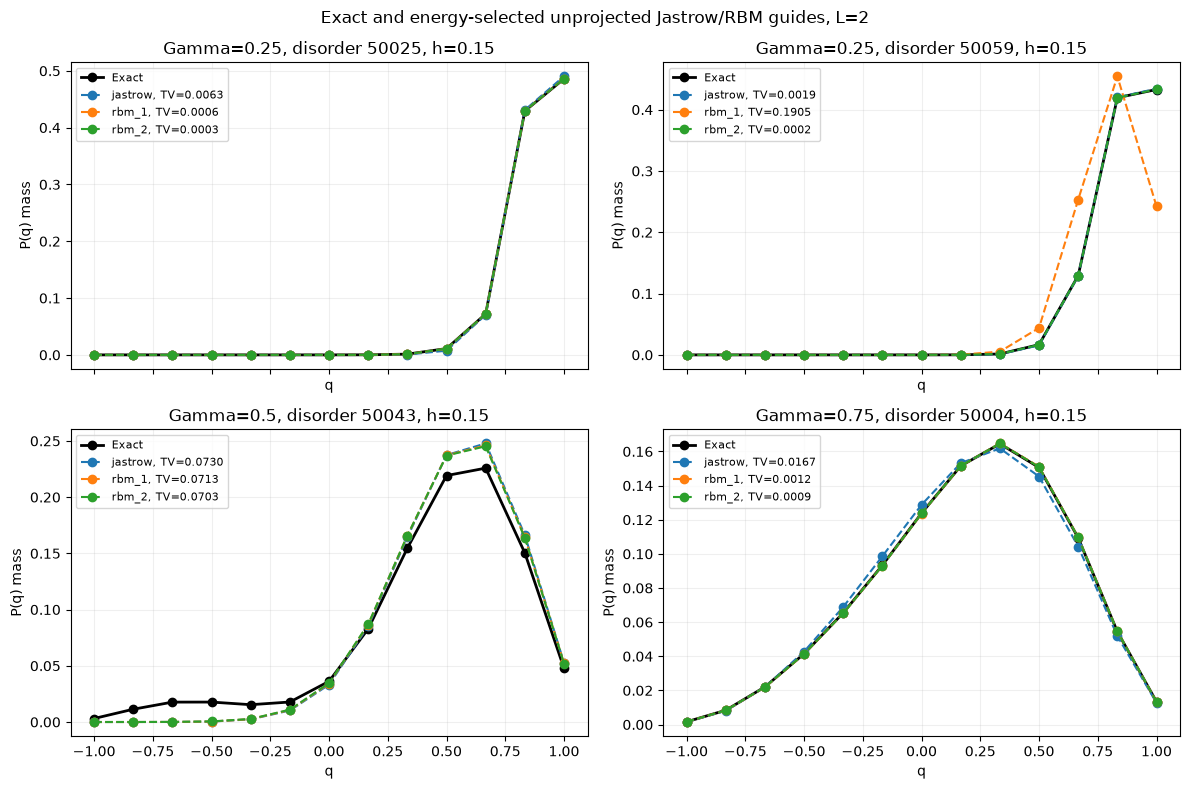

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
folder=root/'data/kagome/ltfim_simple_overlap_v1'
rows=json.loads((folder/'distributions.json').read_text())['rows']
contexts=[(.25,50025),(.25,50059),(.5,50043),(.75,50004)]
kinds=['jastrow','rbm_1','rbm_2']
figures=root/'figures/simple_overlap';figures.mkdir(parents=True,exist_ok=True)
fig,axes=plt.subplots(2,2,figsize=(12,8),sharex=True)
for ax,(g,s) in zip(axes.flat,contexts):
    group=[r for r in rows if (r['gamma'],r['sample_id'])==(g,s)]
    q=np.array(group[0]['q']);ax.plot(q,group[0]['exact_pq'],'ko-',label='Exact',lw=2)
    for kind in kinds:
        r=next(r for r in group if r['kind']==kind and r['selected'])
        ax.plot(q,r['guide_pq'],'o--',label=f"{kind}, TV={r['tv']:.4f}")
    ax.set_title(f'Gamma={g}, disorder {s}, h=0.15');ax.set_xlabel('q');ax.set_ylabel('P(q) mass')
    ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('Exact and energy-selected unprojected Jastrow/RBM guides, L=2')
fig.tight_layout();fig.savefig(figures/'selected_guides_pq.png',dpi=180);fig.savefig(figures/'selected_guides_pq.pdf');plt.show()


## All optimization seeds

Faint curves retain every seed, including fits trapped in another sector. A good
selected curve does not imply reliable optimization. These panels show individual
disorders, so no disorder error bars are attached. TV is half the sum of absolute
bin-probability differences from exact and lies between zero and one.


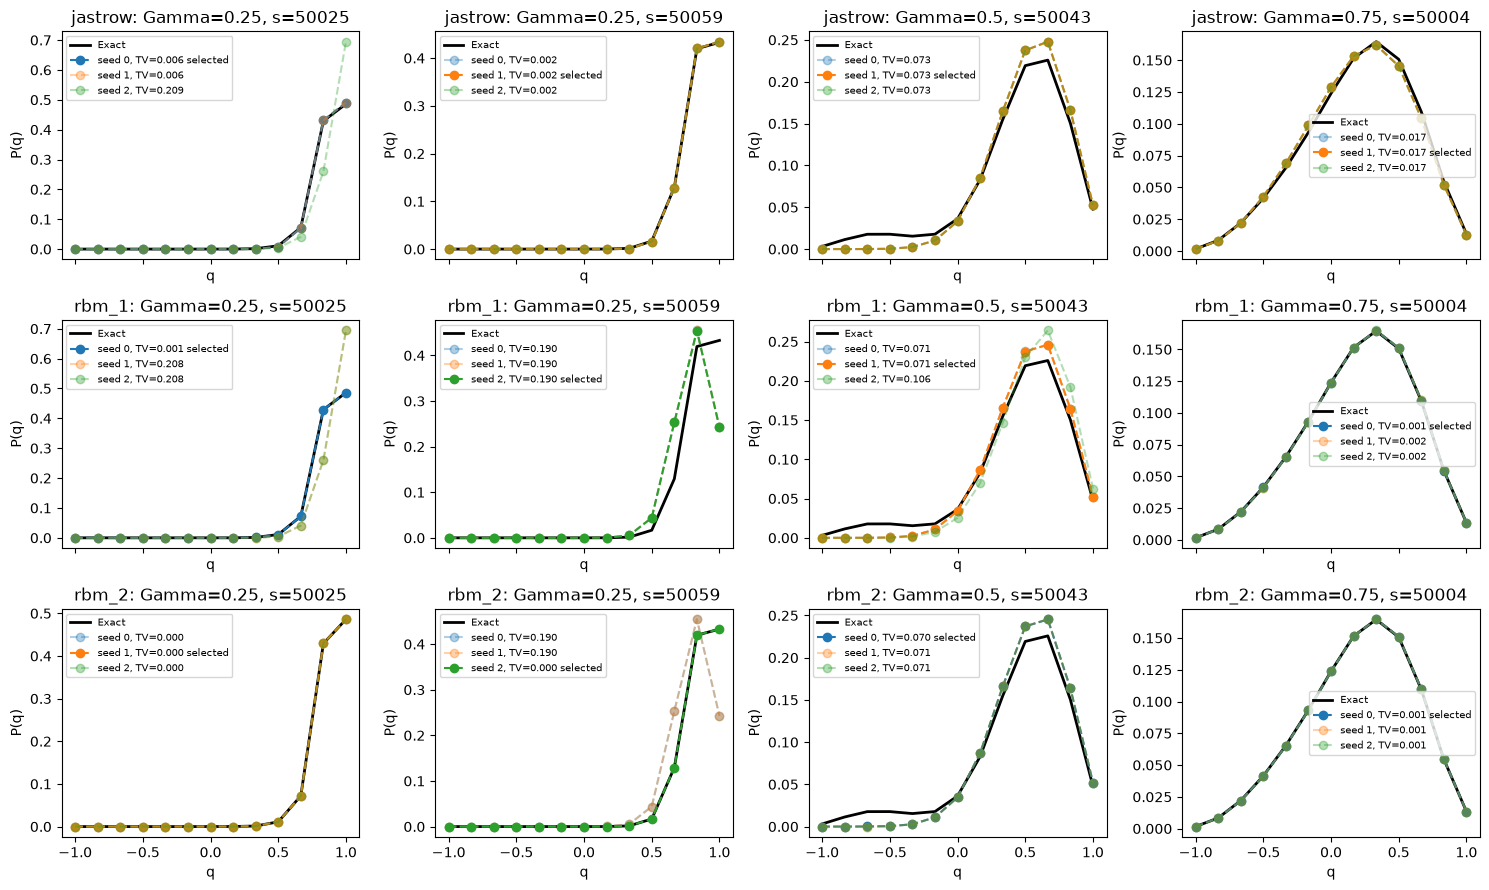

In [2]:
fig,axes=plt.subplots(3,4,figsize=(15,9),sharex=True)
for i,kind in enumerate(kinds):
    for j,(g,s) in enumerate(contexts):
        ax=axes[i,j];group=[r for r in rows if (r['gamma'],r['sample_id'],r['kind'])==(g,s,kind)]
        q=np.array(group[0]['q']);ax.plot(q,group[0]['exact_pq'],'k-',lw=2,label='Exact')
        for r in group:
            ax.plot(q,r['guide_pq'],'o--',alpha=1 if r['selected'] else .35,
                    label=f"seed {r['seed']}, TV={r['tv']:.3f}"+(' selected' if r['selected'] else ''))
        ax.set_title(f'{kind}: Gamma={g}, s={s}');ax.set_xlabel('q');ax.set_ylabel('P(q)');ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(figures/'all_seeds_pq.png',dpi=180);fig.savefig(figures/'all_seeds_pq.pdf');plt.show()


## Guides learned with sampled VMC

These fits used parallel-tempering samples during training. Each panel shows
both seeds and direct/continuation schedules; no seed is selected. The curves
are computed from frozen guide probabilities after training, using L2-only
enumeration to remove histogram sampling noise. In this original campaign,
continuation used more updates than direct training. A separate matched-update
field campaign addresses that confound.


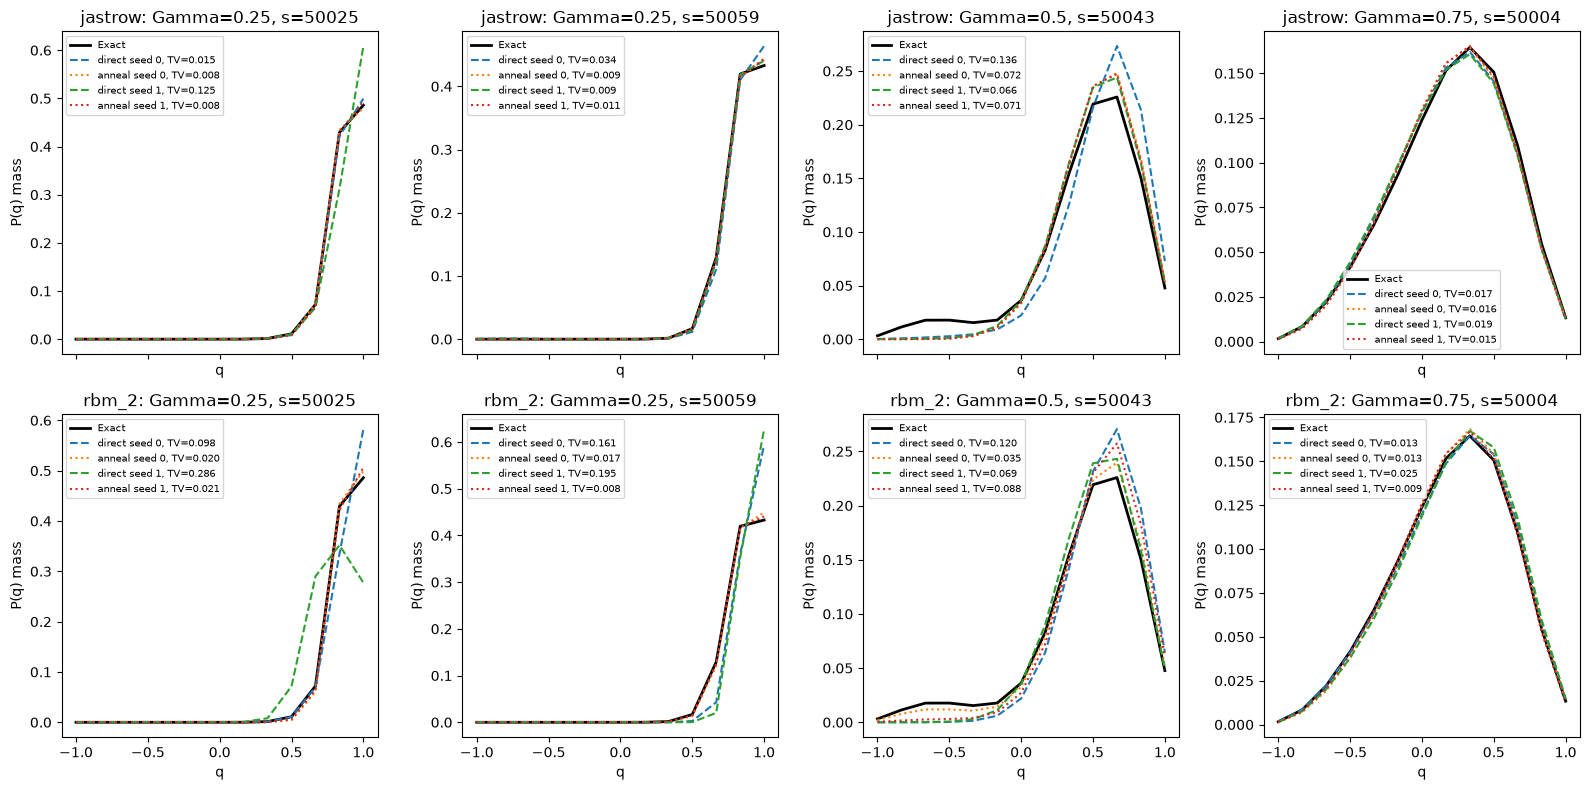

In [3]:
sampled=json.loads((folder/'sampled_distributions.json').read_text())['rows']
fig,axes=plt.subplots(2,4,figsize=(16,8),sharex=True)
for i,kind in enumerate(['jastrow','rbm_2']):
    for j,(g,s) in enumerate(contexts):
        ax=axes[i,j];group=[r for r in sampled if (r['kind'],r['gamma'],r['sample_id'])==(kind,g,s)]
        q=np.array(group[0]['q']);ax.plot(q,group[0]['exact_pq'],'k-',lw=2,label='Exact')
        for r in group:
            ax.plot(q,r['guide_pq'],ls='--' if r['mode']=='direct' else ':',
                label=f"{r['mode']} seed {r['seed']}, TV={r['tv']:.3f}")
        ax.set_title(f'{kind}: Gamma={g}, s={s}');ax.set_xlabel('q');ax.set_ylabel('P(q) mass');ax.legend(fontsize=7)
fig.tight_layout();fig.savefig(figures/'sampled_guides_pq.png',dpi=180);fig.savefig(figures/'sampled_guides_pq.pdf');plt.show()


## Gradually increasing Gamma: physical structure and numerical reliability

Hold $h=0.15$ and each disorder fixed. Fields are 0.50, 0.55, 0.60, 0.65, 0.70,
0.75, 0.85 and 1.00. The eight IDs 50000–50007 form the matched disorder set;
50043 is shown separately as a difficult-case diagnostic. Compute $P_J$ first,
then average across disorders; never pair states from different disorders.
Error bars are one descriptive standard error across disorders, not training
uncertainty or Monte Carlo error.

We track exact overlap variance and gap separately from guide TV, spectral error
and seed reliability. Broad or changing P(q) in L2 is evidence of a finite-size
crossover, not a thermodynamic phase. Convergence failure cannot define a phase.
A candidate field needs both retained physical structure and stable algorithms;
this full-basis fit screen alone cannot qualify GFMC or larger L.


Completed field/disorder contexts: 72 of 72


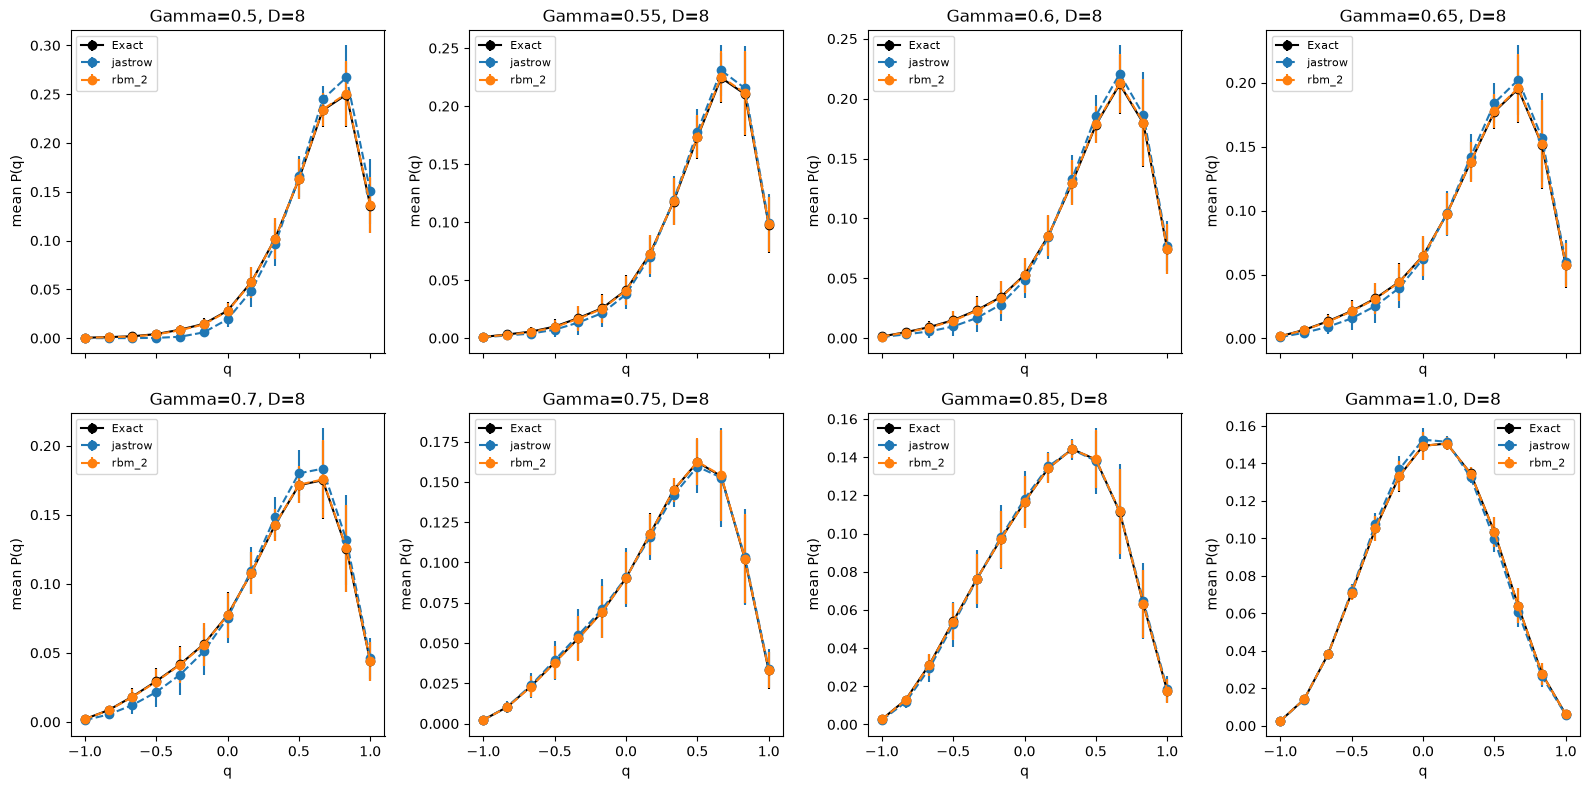

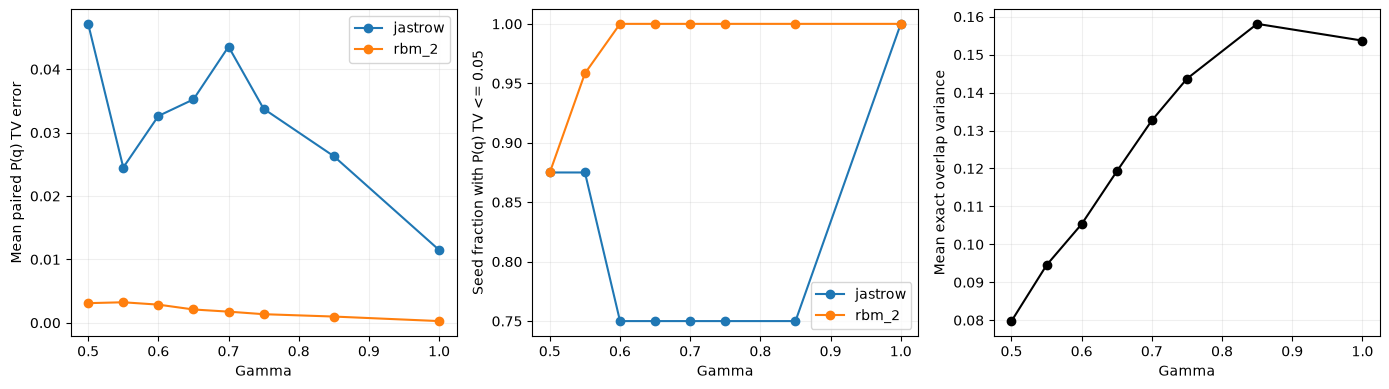

Difficult disorder 50043:
Gamma 0.5 gap 0.028477786317727904 overlap variance 0.1433127878862404 [('jastrow', 0.0729940168535432, 0.2509512905889713), ('rbm_2', 0.0703398412035221, 0.23805360723406227)]
Gamma 0.55 gap 0.03664984971919516 overlap variance 0.18053308687222785 [('jastrow', 0.12068933784073164, 0.3998011282255262), ('rbm_2', 0.030574404546370594, 0.1521805488745425)]
Gamma 0.6 gap 0.04654576047971304 overlap variance 0.21321177882328507 [('jastrow', 0.1810517325668849, 0.5415127524267529), ('rbm_2', 0.006000315449658306, 0.03186724750720627)]
Gamma 0.65 gap 0.059274070733710715 overlap variance 0.23133759145619373 [('jastrow', 0.24257522754388927, 0.6384041075915948), ('rbm_2', 0.0021775489138959173, 0.009376335985721641)]
Gamma 0.7 gap 0.07591076654624018 overlap variance 0.23318165540165128 [('jastrow', 0.0852798718987304, 0.3478271533580209), ('rbm_2', 0.0016126087889206404, 0.0060802336502483526)]
Gamma 0.75 gap 0.09726105403858831 overlap variance 0.2242839480989553 [

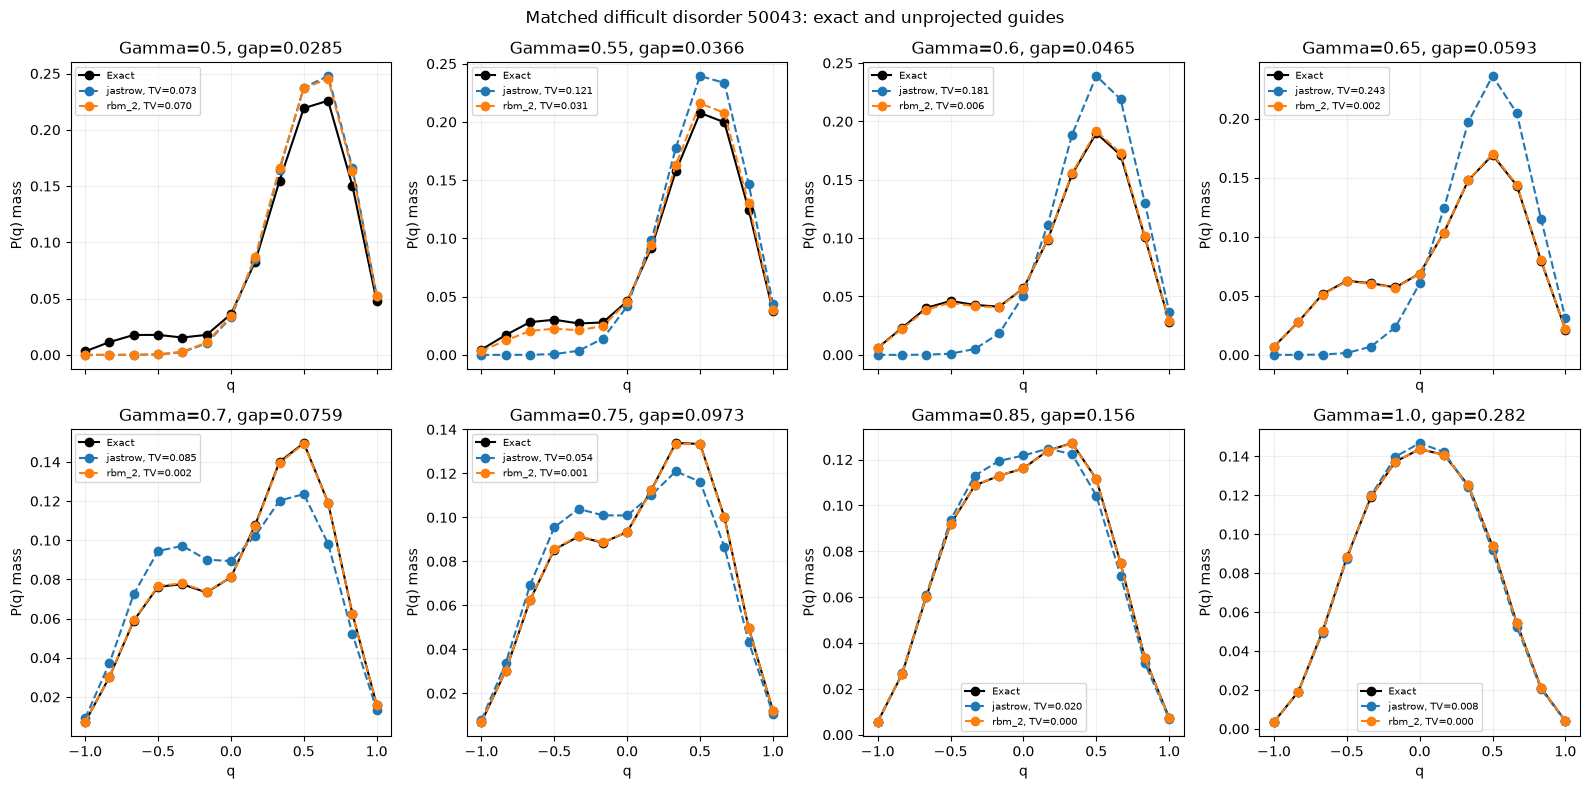

In [4]:
scan=json.loads((folder/'scan_snapshot.json').read_text())
print('Completed field/disorder contexts:',len(scan['rows']),'of 72')
summary=scan['summary'];gammas=sorted(set(r['gamma'] for r in summary))
fig,axes=plt.subplots(2,4,figsize=(16,8),sharex=True)
for ax,g in zip(axes.flat,gammas):
    group=[r for r in summary if r['gamma']==g];q=np.linspace(-1,1,13)
    ax.errorbar(q,group[0]['exact_pq'],yerr=group[0]['exact_disorder_se'],fmt='ko-',label='Exact')
    for r in group:
        ax.errorbar(q,r['guide_pq'],yerr=r['guide_disorder_se'],fmt='o--',label=r['kind'])
    ax.set_title(f"Gamma={g}, D={group[0]['disorders']}");ax.set_xlabel('q');ax.set_ylabel('mean P(q)');ax.legend(fontsize=8)
fig.tight_layout();fig.savefig(figures/'field_scan_pq.png',dpi=180);fig.savefig(figures/'field_scan_pq.pdf');plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,4))
for kind in ['jastrow','rbm_2']:
    group=sorted([r for r in summary if r['kind']==kind],key=lambda r:r['gamma'])
    x=[r['gamma'] for r in group]
    axes[0].plot(x,[r['mean_paired_tv'] for r in group],'o-',label=kind)
    axes[1].plot(x,[r['seed_fraction_pq_tv_below_005'] for r in group],'o-',label=kind)
group=sorted([r for r in summary if r['kind']=='jastrow'],key=lambda r:r['gamma'])
axes[2].plot([r['gamma'] for r in group],[r['mean_overlap_variance'] for r in group],'ko-')
axes[0].set_ylabel('Mean paired P(q) TV error');axes[1].set_ylabel('Seed fraction with P(q) TV <= 0.05')
axes[2].set_ylabel('Mean exact overlap variance')
for ax in axes:ax.set_xlabel('Gamma');ax.grid(alpha=.2)
axes[0].legend();axes[1].legend();fig.tight_layout()
fig.savefig(figures/'field_scan_tradeoff.png',dpi=180);fig.savefig(figures/'field_scan_tradeoff.pdf');plt.show()
print('Difficult disorder 50043:')
for r in sorted([r for r in scan['rows'] if r['sample_id']==50043],key=lambda r:r['gamma']):
    print('Gamma',r['gamma'],'gap',r['exact']['gap'],'overlap variance',r['exact']['variance'],
          [(f['kind'],f['pq_tv'],f['max_spectral_error']) for f in r['fits'] if f['selected']])
fig,axes=plt.subplots(2,4,figsize=(16,8),sharex=True)
hard=sorted([r for r in scan['rows'] if r['sample_id']==50043],key=lambda r:r['gamma'])
for ax,r in zip(axes.flat,hard):
    q=np.array(r['exact']['q']);ax.plot(q,r['exact']['pq'],'ko-',label='Exact')
    for f in r['fits']:
        if f['selected']:ax.plot(q,f['pq'],'o--',label=f"{f['kind']}, TV={f['pq_tv']:.3f}")
    ax.set_title(f"Gamma={r['gamma']}, gap={r['exact']['gap']:.3g}")
    ax.set_xlabel('q');ax.set_ylabel('P(q) mass');ax.legend(fontsize=7);ax.grid(alpha=.2)
fig.suptitle('Matched difficult disorder 50043: exact and unprojected guides')
fig.tight_layout();fig.savefig(figures/'difficult_disorder_scan.png',dpi=180)
fig.savefig(figures/'difficult_disorder_scan.pdf');plt.show()


## Candidate field region

The completed full-basis screen identifies **$\Gamma=0.60$–$0.70$ as an RBM
candidate window**. On disorder 50043 the exact negative-overlap shoulder grows
through this interval while the selected RBM TV error falls from 0.0060 to
0.0016. At $\Gamma=0.65$, TV is 0.0022 and connected-spectrum error is 0.94%.
All three RBM seeds on this disorder have TV below 0.01 from 0.60 onward. Across
the separate eight-disorder ensemble, all 24 RBM seeds have TV below 0.05 from
0.60 onward. These descriptive thresholds do not certify ground-state sampling.

Jastrow remains unreliable here: its selected TV on 50043 rises to 0.243 at
0.65. The apparent window is therefore ansatz-dependent. Negative-overlap weight
alone is not a phase identifier; it can also rise as a distribution approaches
a symmetric paramagnet. The shoulder and two maxima in this small system are
features to follow with size, not evidence of thermodynamic replica symmetry
breaking.

Two independent follow-ups have been launched on AutoDL: equal-update sampled
VMC at $L=2,4$ (1200 updates per fit, direct versus continuation), and CT GFMC
population/time sensitivity over all eight fields. Their live records are under
`data/kagome/ltfim_simple_overlap_v1/sampled/` and `projector/`. This notebook's
field recommendation is based on the completed full-basis screen; it does not
claim those follow-ups have converged.
